## Pipeline To Dowload copernicus data Sentinel-2

**Auteur :** Fiononana  
**Date :** 2025  
**Objectif :** Obtenir la composite annuel Sentinel-2 L2A sur l'Île-de-France.


###  Références & Documentation
- [OpenEO Python Client](https://open-eo.github.io/openeo-python-client/)
- [Copernicus Data Space Ecosystem](https://dataspace.copernicus.eu/)
- [Sentinel-2 L2A – ESA](https://sentinels.copernicus.eu/web/sentinel/missions/sentinel-2)
- [Rasterio Documentation](https://rasterio.readthedocs.io/en/latest/)
- [scikit-learn RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
- [GeoPandas Documentation](https://geopandas.org/en/stable/)

>  **Note environnement** :
> ```bash
> conda create -n classif_env python=3.11
> pip install scikit-learn rasterio geopandas matplotlib numpy
> ```


##  Étape 0 – Imports & dépendances

In [1]:
# ── Librairies standard ──────────────────────────────────────────────────────
import datetime
import json
import os
import subprocess
import pickle
from pathlib import Path

# ── Géospatial ───────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.merge import merge
from rasterio.mask import mask
from shapely.geometry import box

# ── Visualisation ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

# ── OpenEO / Copernicus ──────────────────────────────────────────────────────
import openeo
from openeo.extra.job_management import MultiBackendJobManager, CsvJobDatabase

print(" Tous les imports OK")
print(f"   numpy    {np.__version__}")
print(f"   pandas   {pd.__version__}")
print(f"   rasterio {rasterio.__version__}")
print(f"   openeo   {openeo.__version__}")


 Tous les imports OK
   numpy    2.4.5
   pandas   3.0.1
   rasterio 1.5.0
   openeo   0.49.0


##  Étape 1 – Chemins & Paramètres

> **Référence :** [pathlib – Python docs](https://docs.python.org/3/library/pathlib.html)


In [14]:
# ── Racine du projet ─────────────────────────────────────────────────────────
root = Path(r"D:\ClassificationJardins")

# ── Données géographiques ────────────────────────────────────────────────────
data_ZE      = next(root.rglob("*FondCarte*"))
geojson_path = next(data_ZE.rglob("ZE_IDF.geojson"))
region_path  = next(data_ZE.rglob("Region_IDF_4326.geojson"))

# ── Outputs ──────────────────────────────────────────────────────────────────
data_outputs  = Path(r"C:\Users\Fiononana\Documents\Stacks\outputs_RGB")

TILES_merged_DIR = data_outputs /  "tiles_merged"
JOB_merged_PATH  = data_outputs /  "jobs_merged.csv"


MERGED_TIF  = data_outputs / "merged.tif"
CLIPPED_TIF = data_outputs / "IDF_merged_clipped.tif"

# Nouveau dossier pour le résultat final
output_dir = data_outputs / "masked_sentinel" / "IDF_merged_clipped_masked.tif"


# ── Paramètres Sentinel-2 ────────────────────────────────────────────────────
START_DATE      = datetime.date(2025, 1, 1)
END_DATE        = datetime.date(2025, 12, 31)
S2_BANDS        = ["B02", "B03", "B04", "B08"]
MAX_CLOUD_COVER = 20
PARALLEL_JOBS   = 2


print(" Chemins configurés")


 Chemins configurés


##  Étape 2 – BBox & découpage en tuiles

> **Référence :** [GeoPandas – total_bounds](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.total_bounds.html) | [Shapely box](https://shapely.readthedocs.io/en/stable/manual.html#shapely.geometry.box)


Projection : EPSG:4326
Bounds WGS84 : {'west': 2.303096057237001, 'south': 48.874192077157005, 'east': 2.468798881208994, 'north': 48.983359240163914}
  tile_id      west      south      east      north
0  tile_1  2.303096  48.874192  2.385947  48.928776
1  tile_2  2.385947  48.874192  2.468799  48.928776
2  tile_3  2.303096  48.928776  2.385947  48.983359
3  tile_4  2.385947  48.928776  2.468799  48.983359


C:\Users\Fiononana\AppData\Local\Temp\ipykernel_18312\1707247535.py:48: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
C:\Users\Fiononana\AppData\Local\Temp\ipykernel_18312\1707247535.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


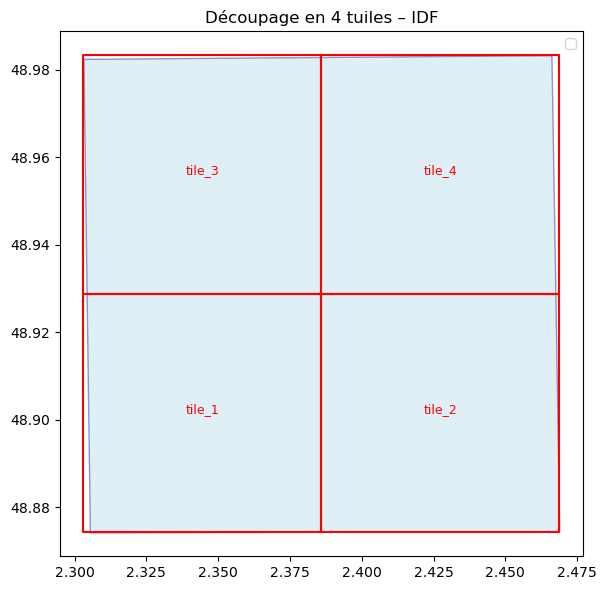

In [8]:
gdf    = gpd.read_file(geojson_path)
bounds = gdf.total_bounds
bbox_Idf = dict(
    west=float(bounds[0]), south=float(bounds[1]),
    east=float(bounds[2]), north=float(bounds[3])
)
print("Projection :", gdf.crs)
print("Bounds WGS84 :", bbox_Idf)

def create_4_tiles(bbox: dict) -> gpd.GeoDataFrame:
    """
    Découpe l'AOI en 4 tuiles (grille 2×2).

    Parameters
    ----------
    bbox : dict  clés west, south, east, north en EPSG:4326

    Returns
    -------
    gpd.GeoDataFrame  avec colonnes tile_id, west, south, east, north, geometry
    """
    w, s, e, n = bbox["west"], bbox["south"], bbox["east"], bbox["north"]
    mx, my = (w + e) / 2, (s + n) / 2
    tiles = [
        ("tile_1", w,  s,  mx, my),   # bas-gauche
        ("tile_2", mx, s,  e,  my),   # bas-droite
        ("tile_3", w,  my, mx, n),    # haut-gauche
        ("tile_4", mx, my, e,  n),    # haut-droite
    ]
    return gpd.GeoDataFrame([
        {"tile_id": tid, "west": w_, "south": s_, "east": e_, "north": n_,
         "geometry": box(w_, s_, e_, n_), "status": "not_started", "id": ""}
        for tid, w_, s_, e_, n_ in tiles
    ], crs="EPSG:4326")

tiles_gdf = create_4_tiles(bbox_Idf)
n_tiles   = len(tiles_gdf)
print(tiles_gdf[["tile_id", "west", "south", "east", "north"]].to_string())

# Visualisation des tuiles
fig, ax = plt.subplots(figsize=(7, 6))
gdf.plot(ax=ax, color="lightblue", edgecolor="navy", alpha=0.4, label="IDF")
tiles_gdf.plot(ax=ax, color="none", edgecolor="red", linewidth=1.5, label="Tuiles")
for _, row in tiles_gdf.iterrows():
    ax.annotate(row["tile_id"], xy=(row.geometry.centroid.x, row.geometry.centroid.y),
                ha="center", fontsize=9, color="red")
ax.set_title("Découpage en 4 tuiles – IDF")
ax.legend()
plt.tight_layout()
plt.show()


## Étape 3 – Connexion OpenEO / Copernicus

> **Référence :** [openeo.connect()](https://open-eo.github.io/openeo-python-client/api.html#openeo.connect) | [CDSE OpenEO endpoint](https://documentation.dataspace.copernicus.eu/APIs/openEO.html)


In [5]:
c = openeo.connect("openeo.dataspace.copernicus.eu").authenticate_oidc()
print("Connecté au Copernicus Data Space Ecosystem")

Visit https://identity.dataspace.copernicus.eu/auth/realms/CDSE/device?user_code=SNYT-QUCD 📋 to authenticate.

✅ Authorized successfully

Authenticated using device code flow.
Connecté au Copernicus Data Space Ecosystem


##  Étape 4 – Fonctions composite Sentinel-2 & indices

> **Référence :**
> - [Sentinel-2 SCL – masque nuages](https://sentinels.copernicus.eu/web/sentinel/technical-guides/sentinel-2-msi/level-2a/algorithm-overview)
> - [MSAVI2 – Qi et al. 1994](https://doi.org/10.1016/0034-4257(94)90134-1)
> - [openeo.load_collection()](https://open-eo.github.io/openeo-python-client/api.html#openeo.DataCube.load_collection)


In [9]:
def sentinel2_yearly_composite(connection, start_date, end_date, spatial_extent):
    """
    Composite médian Sentinel-2 L2A avec masque nuages SCL.

    Parameters
    ----------
    connection     : openeo.Connection
    start_date     : datetime.date
    end_date       : datetime.date
    spatial_extent : dict  (west, south, east, north, crs)

    Returns
    -------
    openeo.DataCube  réduit sur la dimension temporelle (médiane)

    Notes
    -----
    Le masque SCL utilise `to_scl_dilation_mask` (CDSE) pour éliminer :
      - valeurs 2,4,5,6,7 : ombres, végétation, sol nu, eau
      - valeurs 3,8,9,10,11 : nuages dilués, médians, épais, cirrus, neige
    Voir : https://sentinels.copernicus.eu/web/sentinel/technical-guides/sentinel-2-msi/level-2a/algorithm-overview
    """
    temp_ext = [start_date.isoformat(), end_date.isoformat()]
    props    = {"eo:cloud_cover": lambda v: v <= MAX_CLOUD_COVER}

    scl = connection.load_collection(
        "SENTINEL2_L2A",
        spatial_extent=spatial_extent, temporal_extent=temp_ext,
        bands=["SCL"], properties=props,
    )
    cloud_mask = scl.process(
        "to_scl_dilation_mask", data=scl,
        kernel1_size=17, kernel2_size=77,
        mask1_values=[2, 4, 5, 6, 7],
        mask2_values=[3, 8, 9, 10, 11],
        erosion_kernel_size=3,
    )
    s2 = connection.load_collection(
        "SENTINEL2_L2A",
        spatial_extent=spatial_extent, temporal_extent=temp_ext,
        bands=S2_BANDS, properties=props,
    ).mask(cloud_mask)

    # Médiane temporelle
    # Ref : https://open-eo.github.io/openeo-python-client/api.html#openeo.DataCube.reduce_dimension
    return s2.reduce_dimension(dimension="t", reducer="median")


def compute_indices_from_rgbn(rgbn):
    """
    Calcule MSAVI2 à partir d'un cube OpenEO RGBN.

    MSAVI2 = (2*NIR + 1 - sqrt((2*NIR+1)² - 8*(NIR-RED))) / 2
    Ref : Qi et al. (1994) https://doi.org/10.1016/0034-4257(94)90134-1

    Parameters
    ----------
    rgbn : openeo.DataCube  bandes B02, B03, B04, B08 (réflectances DN)

    Returns
    -------
    dict  {"MSAVI2": openeo.DataCube}
    """
    nir   = rgbn.band("B08") * 0.0001
    red   = rgbn.band("B04") * 0.0001
    msavi2 = (2 * nir + 1 - ((2 * nir + 1)**2 - 8 * (nir - red))**0.5) / 2
    msavi2 = msavi2.add_dimension(name="bands", label="MSAVI2", type="bands")
    return {"MSAVI2": msavi2}

print(" Fonctions composite et indices définies")


 Fonctions composite et indices définies


##  Étape 5 – Lancement des jobs OpenEO (RGBN + MSAVI2)

> **Référence :** [MultiBackendJobManager](https://open-eo.github.io/openeo-python-client/batch_jobs.html#multibackendjobmanager) | [Batch Jobs CDSE](https://documentation.dataspace.copernicus.eu/APIs/openEO/Job_config.html)


In [12]:
def _spatial_extent(row):
    """Convertit une ligne GeoDataFrame en dict spatial_extent OpenEO."""    
    return {"west": row["west"], "south": row["south"],
            "east": row["east"], "north": row["north"], "crs": "EPSG:4326"}


def create_merged_job(row, connection, **kwargs):
    """
    Crée un job OpenEO RGBN + MSAVI2 pour une tuile.

    Returns
    -------
    openeo.BatchJob
    """
    se      = _spatial_extent(row)
    rgbn    = sentinel2_yearly_composite(connection, START_DATE, END_DATE, se)
    indices = compute_indices_from_rgbn(rgbn)
    merged  = rgbn.merge_cubes(indices["MSAVI2"])
    return merged.create_job(
        out_format="GTiff",
        title=f"MERGED_{row['tile_id']}",
        description=f"RGBN + MSAVI2 — {row['tile_id']} — {START_DATE} à {END_DATE}",
        job_options={"driver-memory": "4g"},
    )


# Lance les jobs uniquement si merged.tif n'existe pas encore
if not MERGED_TIF.exists():
    print(f"Lancement de {n_tiles} jobs (max {PARALLEL_JOBS} en parallèle)…")
    manager = MultiBackendJobManager(root_dir=str(TILES_merged_DIR), poll_sleep=60)
    manager.add_backend(name="cdse", connection=c, parallel_jobs=PARALLEL_JOBS)
    stats = manager.run_jobs(df=tiles_gdf, start_job=create_merged_job,
                             job_db=str(JOB_merged_PATH))
    print("\n=== Résumé des jobs ===")
    for k, v in stats.items():
        print(f"  {k}: {v}")
else:
    print("Tuiles déjà téléchargées, étape ignorée.")


Lancement de 4 jobs (max 2 en parallèle)…

=== Résumé des jobs ===
  job_db persist: 18
  track_statuses: 10
  start_job call: 4
  job get status: 4
  job_queued_for_start: 4
  job launch: 4
  job start: 4
  run_jobs loop: 10
  sleep: 10
  job describe: 16
  job started running: 5
  job finished: 4
  job download: 4
  files downloaded: 4


##  Étape 6 – Fusion des tuiles (mosaïque)

> **Référence :** [rasterio.merge](https://rasterio.readthedocs.io/en/latest/api/rasterio.merge.html)


In [16]:
if not MERGED_TIF.exists():
    # Lister tous les .tif dans les dossiers job_*
    job_dirs  = [p for p in TILES_merged_DIR.rglob("*")
                 if p.is_dir() and p.name.startswith("job_")]
    tif_paths = []
    for d in job_dirs:
        tif_paths.extend(d.rglob("*.tif"))
    print(f"Tuiles trouvées : {len(tif_paths)}")

    # Fusion avec rasterio.merge
    # Ref : https://rasterio.readthedocs.io/en/latest/api/rasterio.merge.html
    src_files = [rasterio.open(p) for p in tif_paths]
    mosaic, out_transform = merge(src_files)

    out_meta = src_files[0].meta.copy()
    out_meta.update({
        "height": mosaic.shape[1], "width": mosaic.shape[2],
        "transform": out_transform, "driver": "GTiff", "bigtiff": "YES",
    })
    with rasterio.open(MERGED_TIF, "w", **out_meta) as dst:
        dst.write(mosaic)

    for s in src_files:
        s.close()
    print(f"Fusion terminée → {MERGED_TIF}")
else:
    print(" merged.tif déjà présent.")


Tuiles trouvées : 4
Fusion terminée → C:\Users\Fiononana\Documents\Stacks\outputs_RGB\merged.tif


##  Étape 7 – Découpage sur le contour IDF (gdalwarp)

> **Référence :** [gdalwarp – GDAL docs](https://gdal.org/programs/gdalwarp.html) | options `-cutline`, `-crop_to_cutline`, `-dstalpha`


In [12]:
if not CLIPPED_TIF.exists():
    # gdalwarp -cutline : découpe le raster sur un polygone vecteur
    # -crop_to_cutline : réduit l'emprise au polygone
    # -dstalpha        : ajoute une bande alpha pour la transparence hors zone
    # Ref : https://gdal.org/programs/gdalwarp.html
    cmd = [
    "gdalwarp",
    "-cutline",       str(region_path),
    "-crop_to_cutline",
    str(MERGED_TIF),
    str(CLIPPED_TIF),
    ]

    subprocess.run(cmd, check=True)
    print(f"Raster découpé → {CLIPPED_TIF}")
else:
    print(" IDF_merged_clipped.tif déjà présent.")

# Afficher les métadonnées du raster final
with rasterio.open(str(CLIPPED_TIF)) as src:
    print(f"\nRaster clippé :")
    print(f"  Taille   : {src.width} × {src.height} px")
    print(f"  Bandes   : {src.count}")
    print(f"  CRS      : {src.crs}")
    print(f"  Résol.   : {src.res} m")
    print(f"  NoData   : {src.nodata}")


Raster découpé → D:\ClassificationJardins\2_Scripts\outputs_RGB\merged\tiles_merged\outputs\IDF_merged_clipped.tif

Raster clippé :
  Taille   : 15473 × 12539 px
  Bandes   : 5
  CRS      : EPSG:32631
  Résol.   : (10.0, 10.0) m
  NoData   : nan
